# Discrimination decay, leakage, broken monotonicity and concentration

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic (the rate, the size of every test, the power ladder)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- read the power of the ECB test of the AUC against the development AUC and of DeLong's test along a ladder of AUC drops, and see how much a test with 150 defaulters can detect;
- show that the ECB AUC test treats the development AUC as known, measure how much it over-rejects when that AUC was estimated, and check that adding the development variance holds the size;
- measure what the discrimination and stability tests see of a leaked feature, and why DeLong's test almost never rejects on nested models fitted on the comparison sample (2 rejections in 1,000, against the 0.001 that Demler et al. report);
- plant a broken monotonicity in a migration matrix and in a PD curve and read the power of the migration z-tests and of the default-profile test;
- show that the ECB concentration statistic is bounded below its critical value for ten grades, so that it cannot reject however concentrated the grades become, and compare it with the chi-square on the counts.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are four families of case C22 (validating the validator), each planting one defect of known severity in data drawn from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`). The severity ladders are design choices of Contraste; none of them is a statement about a bank.

| Family | Planted defect | Tests it targets |
|---|---|---|
| `discrimination-decay` | the current AUC falls below the development AUC of 0.80, by 0 to 0.08 | the ECB AUC test, DeLong |
| `leakage` | a feature carries the outcome in development and is noise at decision time | the AUC test, the CSI, DeLong on nested models |
| `broken-monotonicity` | a migration cell two notches from the diagonal is more frequent than its neighbour; two grades' PDs are moved past each other | the migration z-tests, the default-profile test |
| `concentration` | a share of every grade's mass moves into the modal grade | the ECB concentration test, the chi-square on the counts |

- **Files read:** `data/derived/C22/discrimination-decay.json`, `leakage.json`, `broken-monotonicity.json` and `concentration.json`: in each, `outputs.simulations` (the rates with their Monte Carlo errors), `outputs.generators` (configuration and truth), `outputs.ladder` and `impact`; the leakage file also holds the published rate of Demler et al. in `outputs.golden`, and the concentration file the bounded statistic in `outputs.exact_curves`.

The next cell loads the four artifacts and prints their engine version and size.

In [2]:
# Load the four families and index their simulations by family and key
LANG = "en"
ROOT = Path("../../..").resolve()
names = ("discrimination-decay", "leakage", "broken-monotonicity", "concentration")
families = {name: json.loads((ROOT / "data" / "derived" / "C22" / f"{name}.json").read_text(encoding="utf-8")) for name in names}
rows = {name: {row["key"]: row for row in fam["outputs"]["simulations"]} for name, fam in families.items()}
decay, leak, mono, conc = (families[name] for name in names)

for name in names:
    fam = families[name]
    print(f"{name:22s} baked by riskvalidation {fam['provenance']['riskvalidation_version']} | {len(rows[name]):2d} simulations | ladder: {fam['outputs']['ladder']['label'][LANG]}")
print("installed:", rv.__version__)

discrimination-decay   baked by riskvalidation 1.0.1 | 21 simulations | ladder: AUC drop
leakage                baked by riskvalidation 1.0.1 | 14 simulations | ladder: leak (shift of the feature for defaulters)
broken-monotonicity    baked by riskvalidation 1.0.1 | 24 simulations | ladder: planted cell / closer neighbour
concentration          baked by riskvalidation 1.0.1 | 12 simulations | ladder: share moved into the modal grade
installed: 1.0.1


## Method

**The ECB AUC test.** With AUC$_\text{init}$ the development AUC and AUC$_\text{curr}$ the current one, the ECB treats the development value as a known number and tests

$$S = \frac{\mathrm{AUC}_\text{init} - \mathrm{AUC}_\text{curr}}{s}, \qquad p = 1 - \Phi(S)$$

with $s^2$ the ECB variance of the current AUC (ECB 2019, section 2.5.4.1 and Annex 3.1). When the development AUC was estimated on a sample independent of the current one, the engine's `disc_auc_vs_initial` accepts its variance and uses $s^2 + s^2_\text{init}$, an extension of the ECB formula that the result states. The binormal generators have known AUCs, $\Phi(\delta/\sqrt 2)$ for a separation $\delta$ (Hanley and McNeil, 1982).

**DeLong's test** compares two AUCs scored on the same obligors and is two-sided; its derivation assumes the model parameters are known, which fails for nested models fitted on the comparison sample (Demler, Pencina and D'Agostino, 2012).

**The migration z-tests** compare each off-diagonal cell $p_{ij}$ of a migration matrix with its neighbour closer to the diagonal, $p_{i,j'}$, with $z = (p_{ij'} - p_{ij})/\sqrt{\mathrm{Var}}$; the engine reports the smallest Holm-adjusted p-value over all cells, because the ECB specifies no multiple-testing control.

**The ECB concentration test** compares the coefficient of variation of the grade frequencies with its development value:

$$S = \frac{\sqrt{K-1}\,(\mathrm{CV}_\text{curr} - \mathrm{CV}_\text{init})}{\sqrt{\mathrm{CV}_\text{curr}^2\,(0.5 + \mathrm{CV}_\text{curr}^2)}}, \qquad p = 1 - \Phi(S)$$

The default-profile test, which compares the shape of the PD curve with the shape the PDs imply, is described in notebook 03 (Tasche, 2013). The steps take the four families in turn, each with one dataset, the power table and a replay of a committed row.

### Part A, step 1: how large an AUC drop is caught

The `discrimination-decay` family lowers the current AUC from the development value of 0.80 by 0 to 0.08, with 150 defaulters and 4,850 survivors. The ECB test knows the development AUC exactly; DeLong compares a champion at 0.80 with a challenger at the lower AUC on the same obligors. The next cell prints the rate at 5% of both along the ladder, and interpolates the drop each one catches with 80% power, to compare with the case's headline numbers.

In [3]:
# Print the power of the ECB AUC test and of DeLong along the AUC-drop ladder and interpolate the drop caught with 80% power
drops = decay["outputs"]["ladder"]["values"]
ecb_power = [rows["discrimination-decay"][f"disc.auc_vs_initial@d{x:g}"]["rates"]["p<0.05"]["rate"] for x in drops]
delong_power = [rows["discrimination-decay"][f"disc.delong@d{x:g}"]["rates"]["p<0.05"]["rate"] for x in drops]
print(f"{'AUC drop':>12s} {'ECB test':>11s} {'DeLong':>8s}")
for x, a, b in zip(drops, ecb_power, delong_power):
    print(f"{x:12.2f} {a:11.3f} {b:8.3f}")
print("drop caught with 80% power, ECB test:", round(float(np.interp(0.8, ecb_power, drops)), 4), "|", "committed:", round(decay["impact"]["ecb_drop80"]["value"], 4))
print("drop caught with 80% power, DeLong:", round(float(np.interp(0.8, delong_power, drops)), 4), "|", "committed:", round(decay["impact"]["delong_drop80"]["value"], 4))

    AUC drop    ECB test   DeLong
        0.00       0.029    0.049
        0.01       0.116    0.081
        0.02       0.255    0.180
        0.03       0.462    0.342
        0.05       0.815    0.716
        0.08       0.991    0.978
drop caught with 80% power, ECB test: 0.0492 | committed: 0.0492
drop caught with 80% power, DeLong: 0.0596 | committed: 0.0596


### Part A, step 2: one dataset of each test

The generator of the `d0.05` rung draws scores with a current AUC of 0.75 against a development AUC of 0.80, and the pair generator draws a champion and a challenger with the same 0.05 gap. The next cell rebuilds both from the committed configuration, draws one dataset of each and runs the engine's tests, as a validator would on one sample.

In [4]:
# Rebuild the generators of the 0.05 rung from the committed configuration, draw one dataset of each and run the two tests
from riskvalidation.generators import BinormalScores
from riskvalidation.validation import disc_auc_vs_initial, disc_delong

gens = decay["outputs"]["generators"]
single = BinormalScores(**gens["binormal-150-d0.05"]["config"])
pair = BinormalScores(**gens["binormal-150-pair-d0.05"]["config"])
print("true current AUC:", round(gens["binormal-150-d0.05"]["truth"]["auc_current"], 4), "|", "development AUC:", round(gens["binormal-150-d0.05"]["truth"]["auc_development"], 4))

sample = single.draw(np.random.default_rng(8))
ecb_result = disc_auc_vs_initial(sample["auc_initial"], sample["risk"], sample["defaults"])
print("ECB test: estimated AUC", round(ecb_result.extras["auc_current"], 4), "| S", round(ecb_result.statistic, 3), "|", "p-value", round(ecb_result.p_value, 4))

both = pair.draw(np.random.default_rng(8))
delong_result = disc_delong(both["risk_1"], both["risk_2"], both["defaults"])
print("DeLong:", "statistic", round(delong_result.statistic, 3), "|", "p-value", round(delong_result.p_value, 4))

true current AUC: 0.75 | development AUC: 0.8
ECB test: estimated AUC 0.7336 | S 3.2 | p-value 0.0007
DeLong: statistic 2.435 | p-value 0.0149


### Part A, step 3: the development AUC is an estimate too

In practice the development AUC was estimated on a development sample, so it carries its own error. The ECB form ignores it. The `development` panel measures the size of the test when nothing changed and the development AUC was estimated on a sample of a given size relative to the current one (the first column is the ratio of the current to the development sample, 0 when the AUC is known), in the ECB form and with the development variance added. The next cell prints both along the panel.

In [5]:
# Print the size of the ECB AUC test when nothing changed, by the size of the development sample, in the ECB form and extended
dev_axis = decay["outputs"]["panels"][2]["axis"][LANG]
print("x axis:", dev_axis)
print(f"{'x':>6s} {'ECB form':>10s} {'extended':>10s}")
for tag in ("m0", "m16", "m4", "m1", "m0.467"):
    row = rows["discrimination-decay"][f"disc.auc_vs_initial@{tag}"]
    extended = rows["discrimination-decay"].get(f"disc.auc_vs_initial@{tag}-extended")
    shown = f"{extended['rates']['p<0.05']['rate']:10.4f}" if extended else f"{'-':>10s}"
    print(f"{row['x']:6.3f} {row['rates']['p<0.05']['rate']:10.4f} {shown}")
print("headline, size at C01's slice ratio:", decay["impact"]["ecb_size_c01_ratio"]["value"])

x axis: current / development sample (0: AUC known)
     x   ECB form   extended
 0.000     0.0423          -
 0.062     0.0452     0.0387
 0.250     0.0633     0.0450
 1.000     0.1120     0.0558
 2.141     0.1703     0.0530
headline, size at C01's slice ratio: 0.17025


The next cell replays one committed row from its seed, the extended form at equal sample sizes (about ten seconds). The extended form needs the development AUC's variance, which the generator returns with each draw; the feed passes it to the test. The ECB form of the same sample sizes is read from the table above.

In [6]:
# Replay the extended form at equal sample sizes from its committed seed
from riskvalidation.harness import simulate

dev_generator = BinormalScores(**gens["binormal-150-m1"]["config"])
extended_feed = lambda d: {"auc_initial": d["auc_initial"], "risk": d["risk"], "defaults": d["defaults"], "auc_initial_variance": d["development_auc_variance"]}
key = "disc.auc_vs_initial@m1-extended"
row = rows["discrimination-decay"][key]
replay = simulate("disc.auc_vs_initial", dev_generator, n_rep=row["n_rep"], seed=row["seed"], feed=extended_feed)
print(f"{key:34s} | replay {replay.rates['p<0.05'].rejections} | committed {row['rates']['p<0.05']['rejections']} | size {replay.rates['p<0.05'].rate:.4f}")

disc.auc_vs_initial@m1-extended    | replay 223 | committed 223 | size 0.0558


### Part B, step 4: what a leak does to the tests

In the `leakage` family a feature shifts for defaulters by the leak $\lambda$ in development and not at decision time, so the model's AUC is inflated in development and falls when the leak disappears. The artifact stores the exact development and current AUCs of each rung, and the rate at which the AUC test and the CSI of the leaked feature fire. The next cell prints them, with the AUC inflation $\mathrm{AUC}_\text{dev} - \mathrm{AUC}_\text{curr}$.

In [7]:
# Print the exact AUC inflation of each leak and the rate at which the AUC test and the CSI fire
leaks = leak["outputs"]["ladder"]["values"]
print(f"{'leak':>5s} {'AUC development':>15s} {'AUC current':>12s} {'inflation':>10s} {'AUC test':>11s} {'CSI':>6s}")
for lam in leaks:
    truth = leak["outputs"]["generators"][f"binormal-150-leak{lam:g}"]["truth"]
    auc_rate = rows["leakage"][f"disc.auc_vs_initial@l{lam:g}"]["rates"]["p<0.05"]["rate"]
    csi_rate = rows["leakage"][f"stability.csi@l{lam:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{lam:5.2f} {truth['auc_development']:15.4f} {truth['auc_current']:12.4f} {truth['auc_development'] - truth['auc_current']:10.4f} {auc_rate:11.3f} {csi_rate:6.3f}")
print("headline, inflation by a leak of 1:", round(leak["impact"]["dev_auc_inflation_l1"]["value"], 4))

 leak AUC development  AUC current  inflation    AUC test    CSI
 0.00          0.6915       0.6915     0.0000       0.046  0.046
 0.25          0.7340       0.6915     0.0426       0.635  0.060
 0.50          0.7734       0.6915     0.0819       0.989  0.079
 1.00          0.8413       0.6915     0.1499       1.000  0.146
 1.50          0.8944       0.6915     0.2029       1.000  0.334
 2.00          0.9332       0.6915     0.2417       1.000  0.581
headline, inflation by a leak of 1: 0.1499


### Part B, step 5: DeLong on nested models

Demler, Pencina and D'Agostino (2012) show that when the second model adds a predictor with no effect to the first and both are fitted on the sample the test uses, the null distribution of DeLong's statistic is not normal and the test rejects far less than its level. Their simulation (Framingham-like data, 8,261 observations of which 621 cases, 1,000 repetitions) found 0.001 at the 5% level. The generator `NestedLda` reproduces the design. The next cell replays the committed row from its seed (about five seconds), compares the count with the published rate through `agrees_with_published`, and prints the non-nested comparison, two independent scores of equal AUC on an independent sample, where the test should hold its level.

In [8]:
# Replay the nested DeLong row, compare it with the published rate and print the non-nested comparison
from riskvalidation.generators import NestedLda
from riskvalidation.harness import Rate, agrees_with_published

leak_gens = leak["outputs"]["generators"]
nested_row = rows["leakage"]["disc.delong@nested"]
replay = simulate("disc.delong", NestedLda(**leak_gens["nested-lda-framingham"]["config"]), n_rep=nested_row["n_rep"], seed=nested_row["seed"])
print("nested models, replay:", replay.rates["p<0.05"].rejections, "of", replay.n_rep, "|", "committed:", nested_row["rates"]["p<0.05"]["rejections"])

study = leak["outputs"]["golden"][0]
cell = study["cells"][0]
ok, z = agrees_with_published(Rate(replay.rates["p<0.05"].rejections, replay.n_rep), cell["published"], study["runs_published"])
print("published rate (Demler et al.):", cell["published"], "|", "measured:", replay.rates["p<0.05"].rate, "| z", round(z, 2), "|", "agrees:", ok)

non_nested = rows["leakage"]["disc.delong@non-nested"]["rates"]["p<0.05"]
print("non-nested scores, independent sample:", round(non_nested["rate"], 4), "(SE", round(non_nested["se"], 4), ")")
print(study["note"]["en"])

nested models, replay: 2 of 1000 | committed: 2
published rate (Demler et al.): 0.001 | measured: 0.002 | z 0.58 | agrees: True
non-nested scores, independent sample: 0.0525 (SE 0.005 )
Quoted: "the significance level for the F-test is close to the nominal 0.05 level, whereas it is 0.001 for the DeLong test".


### Part C, step 6: the planted monotonicity

A migration matrix should not have a cell two notches from the diagonal that is more frequent than its closer neighbour. The generator takes a decaying seven-grade matrix and sets one cell, grade 4 to grade 2, to a multiple of its neighbour, grade 4 to grade 3. The next cell builds the base and the planted matrix with the engine's `decaying_matrix` and `break_monotonicity` and prints the row that changes.

In [9]:
# Build the base and the planted migration matrix and print the row of grade 4
from riskvalidation.generators import break_monotonicity, decaying_matrix

base = decaying_matrix(7)
planted = break_monotonicity(base, 3, 1, 2.0)
print("row of grade 4, base:   ", np.round(base[3], 4))
print("row of grade 4, planted:", np.round(planted[3], 4))
print("cell 4 to 2 over its neighbour, 4 to 3:", round(float(planted[3, 1] / planted[3, 2]), 3))
committed_matrix = np.array(mono["outputs"]["generators"]["migrations-7-500-r2"]["config"]["matrix"])
print("equals the committed matrix:", bool(np.allclose(planted, committed_matrix)))

row of grade 4, base:    [0.0143 0.0286 0.0571 0.8    0.0571 0.0286 0.0143]
row of grade 4, planted: [0.0143 0.1143 0.0571 0.7143 0.0571 0.0286 0.0143]
cell 4 to 2 over its neighbour, 4 to 3: 2.0
equals the committed matrix: True


### Part C, step 7: the z-tests on one sample, and their power

The next cell draws 500 obligors per grade from the planted matrix and runs `rating_migration_ztests`. The statistic is the number of cells whose raw p-value is below 5%, the p-value is the smallest Holm-adjusted one, and the cell with the smallest adjusted p-value is the planted one, which the test finds from the counts alone. It then replays the committed row for the ratio of 2 with 500 obligors per grade, and prints the power of the test by ratio for 500 and 2,000 obligors per grade.

In [10]:
# Draw one sample from the planted matrix, run the migration z-tests, replay the committed row and print the power by ratio
from riskvalidation.generators import Migrations
from riskvalidation.validation import rating_migration_ztests

mono_gens = mono["outputs"]["generators"]
migrations = Migrations(**mono_gens["migrations-7-500-r2"]["config"])
counts = migrations.draw(np.random.default_rng(3))["counts"]
result = rating_migration_ztests(counts)
worst = min(result.extras["cells"], key=lambda cell: cell["p_holm"])
print("cells with a raw p below 5%:", int(result.statistic), "|", "smallest Holm-adjusted p-value:", f"{result.p_value:.2e}")
print("cell with the smallest adjusted p: grade", worst["from"], "to grade", worst["to"], "| z", round(float(worst["z"]), 2))

row = rows["broken-monotonicity"]["rating.migration_ztests@r2-n500"]
replay = simulate("rating.migration_ztests", migrations, n_rep=row["n_rep"], seed=row["seed"])
print("replay of the ratio 2 row:", replay.rates["p<0.05"].rejections, "|", "committed:", row["rates"]["p<0.05"]["rejections"])

ratios = mono["outputs"]["ladder"]["values"]
print(f"{'ratio':>6s} {'500':>8s} {'2000':>8s}   ({'power at 5%, obligors per grade'})")
for r in ratios:
    print(f"{r:6.2f} " + " ".join(f"{rows['broken-monotonicity'][f'rating.migration_ztests@r{r:g}-n{n}']['rates']['p<0.05']['rate']:8.3f}" for n in (500, 2000)))

cells with a raw p below 5%: 1 | smallest Holm-adjusted p-value: 4.06e-04
cell with the smallest adjusted p: grade 4 to grade 2 | z -4.27
replay of the ratio 2 row: 1110 | committed: 1110
 ratio      500     2000   (power at 5%, obligors per grade)
  1.00    0.001    0.001
  1.25    0.013    0.096
  1.50    0.079    0.657
  2.00    0.555    1.000
  3.00    0.997    1.000
  4.00    1.000    1.000


### Part C, step 8: two PDs moved past each other

The second defect of the family keeps the PD curve's level and breaks its order: the true PDs of grades 3 and 4 are moved toward each other and past each other by a fraction $s$ (0 unchanged, 1 swapped), and the tests are given the original PDs. The default-profile test looks at the shape, so it should see this defect where it was blind to a level. The next cell prints its power along the swap, next to the chi-square over grades, and rebuilds the swapped PDs from the committed configuration.

In [11]:
# Print the true and applied PDs of the swapped rung and the power of the default-profile and chi-square tests along the swap
swap_config = mono_gens["grades-7-swap1"]["config"]
print("applied PDs:", swap_config["pd_forecast"][0])
print("true PDs:   ", swap_config["pd_true"][0])
swaps = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)
print(f"{'s':>5s} {'default profile':>19s} {'chi-square':>12s}")
for s in swaps:
    profile = rows["broken-monotonicity"][f"pd.default_profile@swap{s:g}"]["rates"]["p<0.05"]["rate"]
    chi2 = rows["broken-monotonicity"][f"pd.chi2_grades@swap{s:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{s:5.1f} {profile:19.3f} {chi2:12.3f}")

applied PDs: [0.002, 0.005, 0.01, 0.02, 0.04, 0.08, 0.16]
true PDs:    [0.002, 0.005, 0.02, 0.01, 0.04, 0.08, 0.16]
    s     default profile   chi-square
  0.0               0.044        0.056
  0.2               0.095        0.090
  0.4               0.232        0.226
  0.6               0.536        0.493
  0.8               0.787        0.769
  1.0               0.952        0.937


### Part D, step 9: a bounded statistic

The `concentration` family moves a share of every grade's mass into the modal grade of ten grades. The statistic of the ECB concentration test depends only on the grade frequencies, through their coefficients of variation, and not on the number of obligors. Its largest possible value therefore depends only on the development frequencies. The next cell reads those frequencies from the committed generator, evaluates the engine's `rating_hhi` on a grid of 401 shares from 0 to 1 and prints the largest statistic and the p-value it gives, beside the critical value of 1.645.

In [12]:
# Evaluate the ECB concentration test on a grid of shares moved into the modal grade and find the largest statistic
from riskvalidation.generators import concentrate
from riskvalidation.validation.rating_system import concentration, rating_hhi

initial = np.array(conc["outputs"]["generators"]["grades-10-c0.5"]["config"]["initial"])
cv_initial, hi_initial = concentration(initial)
shares = np.linspace(0.0, 1.0, 401)
statistics = np.array([rating_hhi(concentrate(initial, s), initial).statistic for s in shares])
best = int(np.argmax(statistics))
print("development frequencies:", initial.tolist(), "| CV", round(cv_initial, 4))
print("largest statistic:", round(float(statistics[best]), 4), "at the share", shares[best], "|", "committed headline:", round(conc["impact"]["hhi_max_statistic"]["value"], 4))
print("smallest p-value it can give:", round(float(stats.norm.sf(statistics.max())), 4), "|", "critical value at 5%:", round(float(stats.norm.isf(0.05)), 4))
print("statistic with all the mass in the modal grade (share 1):", round(float(statistics[-1]), 4))

development frequencies: [0.02, 0.05, 0.1, 0.15, 0.2, 0.18, 0.13, 0.09, 0.05, 0.03] | CV 0.6017
largest statistic: 1.0913 at the share 0.3725 | committed headline: 1.0913
smallest p-value it can give: 0.1376 | critical value at 5%: 1.6449
statistic with all the mass in the modal grade (share 1): 0.7781


### Part D, step 10: which setups can reject, and how it compares with the chi-square

The artifact stores the statistic as a function of the current coefficient of variation for four setups: ten grades with an initial CV of 0.3, 0.6 and 1.0, and twenty-six grades with 0.6. The next cell prints the largest value of each, to see which can cross 1.645, and then the power of the ECB test and of the chi-square test of homogeneity on the grade counts along the ladder of shares moved.

In [13]:
# Print the largest value of each committed statistic curve and the power of the ECB test and of the chi-square along the ladder
critical_value = stats.norm.isf(0.05)
for series in conc["outputs"]["exact_curves"][0]["series"]:
    top = max(y for y in series["y"] if y is not None)
    grades_k, cv_initial_k = series["id"][1:].split("-cv")
    print(f"{grades_k:>3s} grades, initial CV {cv_initial_k:4s} largest statistic {top:.3f} | can exceed 1.645: {top > critical_value}")

moved = conc["outputs"]["ladder"]["values"]
print(f"{'share moved':>14s} {'ECB test':>11s} {'chi-square':>12s}")
for s in moved:
    hhi_rate = rows["concentration"][f"rating.hhi@c{s:g}"]["rates"]["p<0.05"]["rate"]
    chi2_rate = rows["concentration"][f"stability.chi2@c{s:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{s:14.2f} {hhi_rate:11.3f} {chi2_rate:12.3f}")

 10 grades, initial CV 0.3  largest statistic 1.756 | can exceed 1.645: True
 10 grades, initial CV 0.6  largest statistic 1.094 | can exceed 1.645: False
 10 grades, initial CV 1    largest statistic 0.709 | can exceed 1.645: False
 26 grades, initial CV 0.6  largest statistic 1.823 | can exceed 1.645: True
   share moved    ECB test   chi-square
          0.00       0.000        0.053
          0.01       0.000        0.082
          0.02       0.000        0.234
          0.05       0.000        0.948
          0.10       0.000        1.000
          0.50       0.000        1.000


### Step 11: the four power curves, drawn

The last cell draws one panel per family: the ECB AUC test and DeLong against the AUC drop, the AUC test and the CSI against the leak, the migration z-tests against the planted ratio for two sample sizes, and the ECB concentration test against the chi-square on the counts. Each point is a rate with its Wilson interval; the dashed line is the nominal 5%.

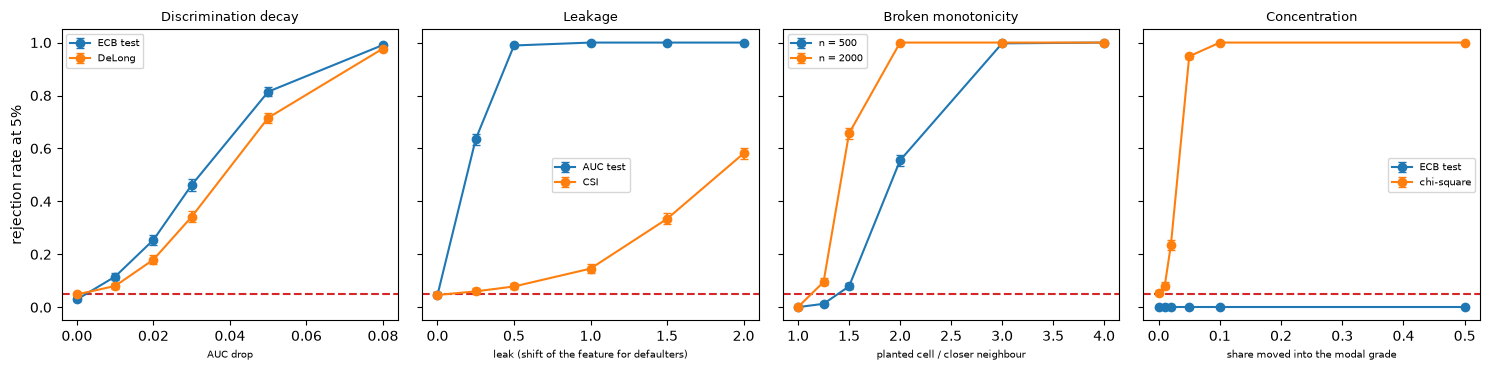

In [14]:
# Draw the power curves of the four families with Wilson intervals
panels = (
    ("Discrimination decay", "discrimination-decay", drops, "d", (("disc.auc_vs_initial", "ECB test"), ("disc.delong", "DeLong")), decay["outputs"]["ladder"]["label"][LANG]),
    ("Leakage", "leakage", leaks, "l", (("disc.auc_vs_initial", "AUC test"), ("stability.csi", "CSI")), leak["outputs"]["ladder"]["label"][LANG]),
    ("Broken monotonicity", "broken-monotonicity", ratios, "r", (("rating.migration_ztests", None),), mono["outputs"]["ladder"]["label"][LANG]),
    ("Concentration", "concentration", moved, "c", (("rating.hhi", "ECB test"), ("stability.chi2", "chi-square")), conc["outputs"]["ladder"]["label"][LANG]),
)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, (title, family, ladder_values, letter, tests, xlabel) in zip(axes, panels):
    for index, (test, label) in enumerate(tests):
        if family == "broken-monotonicity":
            series = [(f"{test}@r{{x:g}}-n{n}", f"n = {n}") for n in (500, 2000)]
        else:
            series = [(f"{test}@{letter}{{x:g}}", label)]
        for k, (pattern, name) in enumerate(series):
            points = [rows[family][pattern.format(x=x)]["rates"]["p<0.05"] for x in ladder_values]
            rate = np.array([p["rate"] for p in points])
            low = np.array([p["wilson_low"] for p in points])
            high = np.array([p["wilson_high"] for p in points])
            ax.errorbar(ladder_values, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, color=f"C{index + k}", label=name)
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xlabel, fontsize=7)
    ax.legend(fontsize=7)
axes[0].set_ylabel("rejection rate at 5%")
fig.tight_layout()
plt.show()

## Results

- **Decay: a drop of 5 AUC points is caught four times in five, and of 2 points one time in four.** With 150 defaulters, the ECB test fires 11.6% of the time for a drop of 0.01, 25.5% for 0.02, 46.2% for 0.03, 81.5% for 0.05 and 99.1% for 0.08; DeLong fires 8.1%, 18.0%, 34.2%, 71.6% and 97.8%. Interpolated, 80% power needs a drop of 0.0492 for the ECB test and a gap of 0.0596 for DeLong, which is comparing two estimated AUCs and not one estimate with a number. With no drop the ECB test rejects 2.9% in this ladder, and 3.4% and 4.2% in the two other rows of the artifacts with a known development AUC (notebook 02 and Part A, step 3): a size at or a little under 5%, not above it. On one dataset of the 0.05 rung the ECB test gave an estimated AUC of 0.734 (the truth is 0.75), S = 3.20 and p = 0.0007, and DeLong p = 0.015.
- **Decay: the development AUC is an estimate, and the ECB form ignores it.** With nothing changed, the ECB form rejects 4.2% when the development AUC is known, 11.2% when it was estimated on a sample as large as the current one, and 17.0% when the current sample is 2.14 times the development one (the ratio of C01's slices). Adding the development variance brings those two to 5.6% and 5.3%. The replay of the extended form gives the committed count exactly (223).
- **Leakage: the AUC test sees it, the CSI of the leaked feature barely does.** A leak of 0.5 inflates the development AUC by 0.082 and the AUC test fires 98.9% of the time; the CSI of the leaked feature fires 7.9%, and 14.6% at a leak of 1, which inflates the AUC by 0.150. The feature's own distribution moves too little to alarm a stability index: leakage shows as a discrimination drop out of time, not as drift in the input.
- **Leakage: DeLong on nested models almost never rejects.** The replay gives 2 rejections in 1,000 at the 5% level, against the 0.001 of Demler et al. (z = 0.58, agreement), and for non-nested scores on an independent sample the test rejects 5.25% (SE 0.50 points). Comparing a model with a version of itself with an extra predictor, on the sample both were fitted to, is not what the test was built for.
- **Monotonicity: the planted cell is found, but not often with 500 per grade.** A cell twice its closer neighbour (0.114 against 0.057) was found in one sample with a z of -4.27 and a Holm-adjusted p-value of 0.0004, yet over repetitions the test fires 55.5% of the time at that ratio with 500 obligors per grade, 7.9% at 1.5 and 1.3% at 1.25, and 100%, 65.7% and 9.6% with 2,000. At no defect it rejects 0.1%: Holm's control over 42 cells makes it conservative. The replay of the ratio 2 row gives 1,110, the committed count.
- **Monotonicity: swapped PDs are seen by the shape test and by the chi-square alike.** With grades 3 and 4 swapped, the default-profile test fires 95.2% and the chi-square over grades 93.7%; at half the way, 53.6% and 49.3%. The profile test, blind to a uniform level (notebook 03), sees a change of order.
- **Concentration: the ECB statistic cannot reject for these ten grades.** The development frequencies have a coefficient of variation of 0.602. Evaluated with the engine over 401 shares, the statistic peaks at 1.0913 (at a share of 0.3725), the committed headline, and gives a smallest p-value of 0.138; with all the mass in the modal grade it is 0.778, lower. The critical value at 5% is 1.645, so the ECB test rejected 0% of the time at every rung, including half the mass moved. Of the four setups stored, the statistic exceeds 1.645 only for ten grades with an initial CV of 0.3 (1.756) and for twenty-six grades with 0.6 (1.823).
- **A test on the counts sees what the bounded statistic cannot.** The chi-square of homogeneity on the grade counts rejects 5.3% with nothing moved, 23.4% with 2% moved and 94.8% with 5% moved, against 0% for the ECB test throughout.

What this notebook does not show: power at sample sizes other than the ones in the ladders, or defects other than the planted ones. The DeLong replay depends on the generator's design of Demler et al. (a single added predictor with no effect). A bounded statistic is a property of this test's formula for these frequencies, not a verdict on the ECB's wish to monitor concentration.

## Summary

- The ECB AUC test catches a drop of 5 AUC points with 80% power on 150 defaulters, and a gap of 6 points with DeLong; a drop of 2 points goes unseen three times in four.
- The ECB test treats the development AUC as a known number: when it was estimated on a sample as large as the current one, the test rejects 11.2% of the time with nothing changed, and 5.6% when its variance is added.
- A leak shows as a discrimination drop out of time (AUC test 98.9% at a leak of 0.5) and hardly as drift in the feature (CSI 7.9%); DeLong on nested models fitted on one sample rejects 2 times in 1,000, as Demler et al. found.
- The migration z-tests find a cell twice its neighbour 55.5% of the time with 500 obligors per grade and always with 2,000; the default-profile test sees a swap of two PDs that it cannot see in a uniform level.
- The ECB concentration statistic peaks at 1.0913 for these ten grades, below the 1.645 it needs, so it never rejects; the chi-square on the counts rejects 94.8% of the time with 5% of the mass moved.

**What to try next.** Rebuild the concentration setup with twenty-six grades (`GradeFrequencies`, `concentrate`) and find the share at which the ECB statistic first exceeds 1.645; then read notebook 07, which sets these measurements beside the literature.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.4.1, 2.5.5.2 and 2.5.5.3 and Annex 3.1 (the AUC against the initial AUC, the migration z-tests, the concentration test). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Demler, O. V., Pencina, M. J. and D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4): the default-profile test. https://doi.org/10.21314/jcr.2013.169
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifacts.